Columnas originales:
['fecha', 'temperatura', 'humedad', 'presion', 'radiacion', 'precipitacion', 'precipitacion_acum_diaria', 'veloc_de_viento_max_10m', 'veloc_de_viento_min_10m', 'veloc_de_viento_prom_10m', 'direccion_de_viento_a_10m', 'direccion_a_10m', 'veloc_de_viento_max_2m', 'veloc_de_viento_min_2m', 'veloc_de_viento_prom_2m', 'direccion_de_viento_a_2m', 'direccion_a_2m', 'evaporimetro', 'evaporacion_acum_diaria']


/tmp/ipykernel_3822486/3814546769.py:71: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["fecha"] = pd.to_datetime(



Tipos de datos:
radiacion                   float64
temperatura                 float64
humedad                     float64
presion                     float64
precipitacion               float64
veloc_de_viento_prom_10m    float64
dtype: object

Valores faltantes después de conversión:
radiacion                     65
temperatura                  125
humedad                      101
presion                     1761
precipitacion                 39
veloc_de_viento_prom_10m       0
dtype: int64

Inicio test: 2026-02-15 00:00:00
Fin teórico: 2026-02-22 00:00:00
Último timestamp esperado: 2026-02-21 23:45:00

Cantidad de timestamps esperados:
672

Filas originales en test:
668

Cantidad de timestamps faltantes:
4

Timestamps faltantes:
DatetimeIndex(['2026-02-18 06:45:00', '2026-02-18 09:15:00',
               '2026-02-18 10:00:00', '2026-02-21 09:45:00'],
              dtype='datetime64[ns]', freq=None)

Tamaño final de test:
672

NaN restantes en test:
radiacion                   0
tem

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]


Predicción:
(672,)

MÉTRICAS CHRONOS-2 + EXÓGENAS
MAE  : 51.7206
RMSE : 106.7814
WAPE : 26.25 %


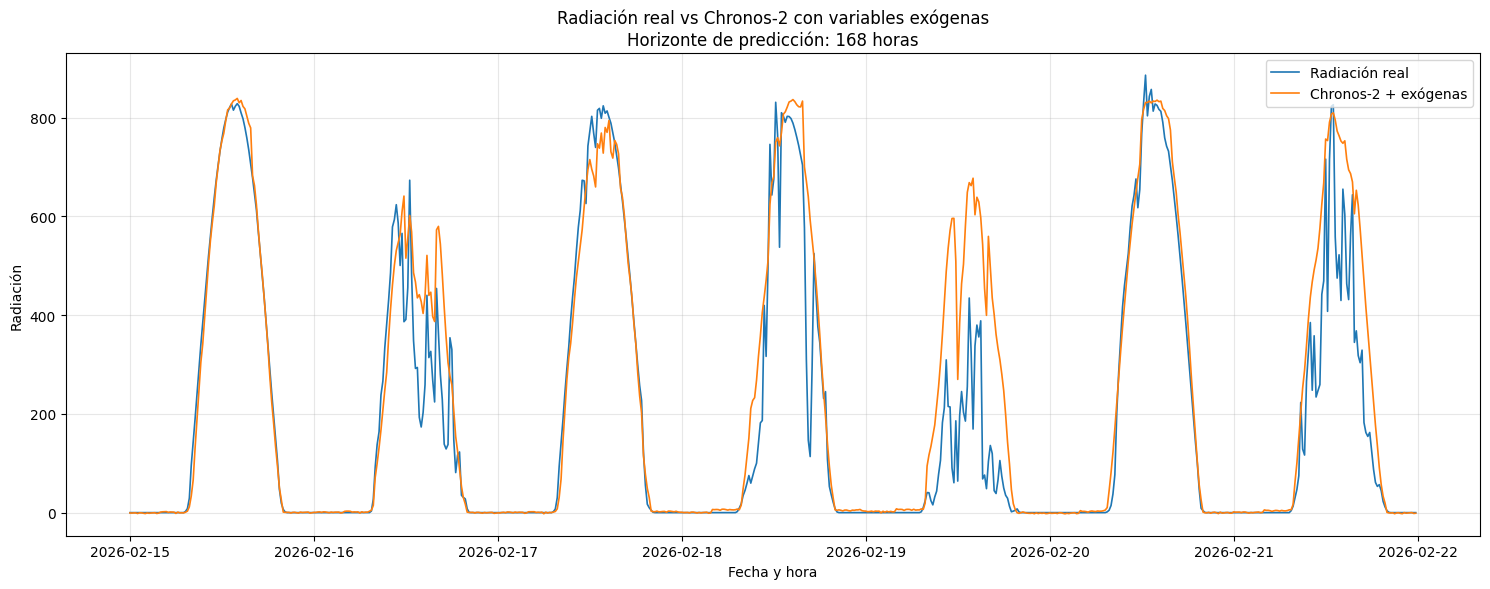

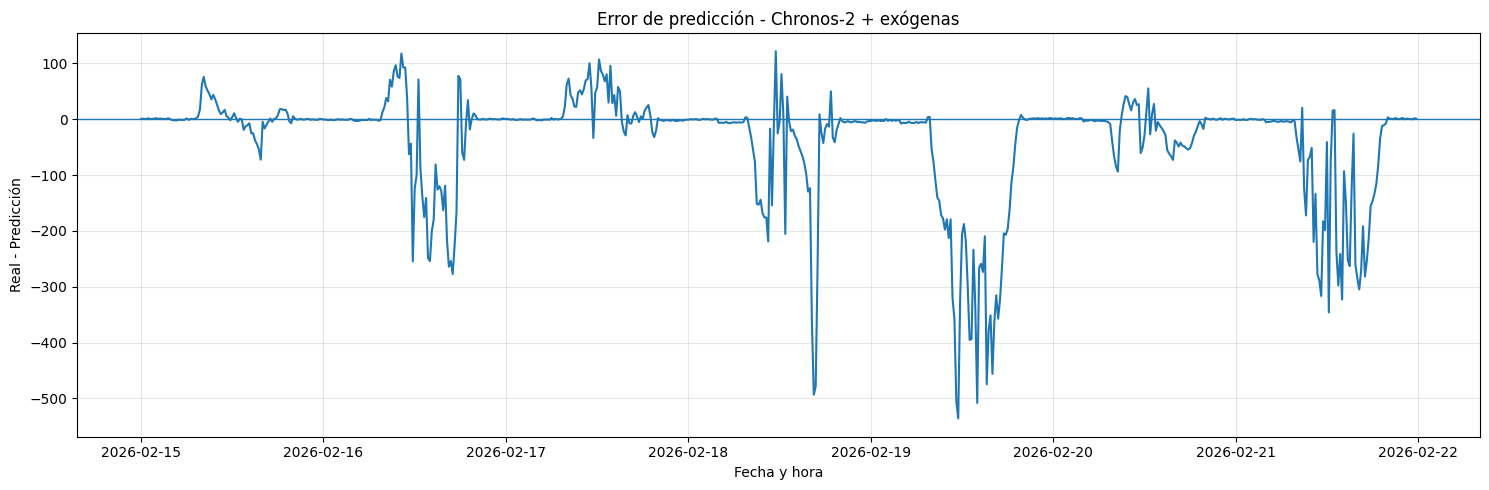


Proceso terminado.


In [21]:
# ============================================================
# CHRONOS-2 + VARIABLES EXÓGENAS
# Pronóstico de radiación solar - horizonte de 7 días
# ============================================================

# Si hace falta instalar:
# !pip install -U "chronos-forecasting>=2.0"

import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from chronos import Chronos2Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

ARCHIVO = "unificada.csv"

FECHA_INICIO_TEST = "2026-02-15 00:00:00"

HORAS_PREDICCION = 168
#HORAS_PREDICCION = 24

# 4 registros por hora porque la frecuencia es de 15 minutos
PASOS_POR_HORA = 4

PREDICTION_LENGTH = HORAS_PREDICCION * PASOS_POR_HORA
# 168 * 4 = 672






TARGET = "radiacion"

EXOGENAS = [
    "temperatura",
    "humedad",
    "presion",
    "precipitacion",
    "veloc_de_viento_prom_10m"
]


# ============================================================
# 2. CARGAR ARCHIVO
# ============================================================

# Detectar automáticamente el separador
df = pd.read_csv(
    ARCHIVO,
    sep=None,
    engine="python"
)

print("Columnas originales:")
print(df.columns.tolist())


# ============================================================
# 3. COLUMNA DE FECHA
# ============================================================

# CAMBIAR "fecha" SI TU COLUMNA TIENE OTRO NOMBRE
df["fecha"] = pd.to_datetime(
    df["fecha"],
    errors="coerce"
)

# Eliminar filas sin fecha válida
df = df.dropna(subset=["fecha"])

df = (
    df
    .sort_values("fecha")
    .drop_duplicates(subset=["fecha"])
    .reset_index(drop=True)
)


# ============================================================
# 4. LIMPIAR COLUMNAS NUMÉRICAS
# ============================================================

COLUMNAS_NUMERICAS = [TARGET] + EXOGENAS

for col in COLUMNAS_NUMERICAS:

    # Convierte primero a texto
    df[col] = df[col].astype(str)

    # Corrige valores como:
    # "1,012.1" --> "1012.1"
    df[col] = df[col].str.replace(
        ",",
        "",
        regex=False
    )

    # Convierte a número
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


print("\nTipos de datos:")
print(df[COLUMNAS_NUMERICAS].dtypes)

print("\nValores faltantes después de conversión:")
print(df[COLUMNAS_NUMERICAS].isna().sum())


# ============================================================
# 5. DEFINIR PERÍODO DE TEST
# ============================================================

fecha_inicio_test = pd.Timestamp(FECHA_INICIO_TEST)

fecha_fin_test = (
    fecha_inicio_test +
    pd.Timedelta(hours=HORAS_PREDICCION)
)

print("\nInicio test:", fecha_inicio_test)
print("Fin teórico:", fecha_fin_test)

# El último timestamp esperado es:
ultimo_timestamp = (
    fecha_inicio_test +
    pd.Timedelta(minutes=15 * (PREDICTION_LENGTH - 1))
)

print("Último timestamp esperado:", ultimo_timestamp)


# ============================================================
# 6. CREAR GRILLA EXACTA DE 672 TIMESTAMPS
# ============================================================

indice_test = pd.date_range(
    start=fecha_inicio_test,
    periods=PREDICTION_LENGTH,
    freq="15min"
)

print("\nCantidad de timestamps esperados:")
print(len(indice_test))


# ============================================================
# 7. EXTRAER TEST Y REINDEXAR
# ============================================================

df_test_original = df[
    (df["fecha"] >= fecha_inicio_test) &
    (df["fecha"] < fecha_fin_test)
].copy()

print("\nFilas originales en test:")
print(len(df_test_original))


# Revisar timestamps faltantes
timestamps_reales = pd.DatetimeIndex(
    df_test_original["fecha"]
)

faltantes = indice_test.difference(
    timestamps_reales
)

print("\nCantidad de timestamps faltantes:")
print(len(faltantes))

if len(faltantes) > 0:
    print("\nTimestamps faltantes:")
    print(faltantes)


# Reindexar para tener exactamente 672 posiciones
df_test = (
    df_test_original
    .set_index("fecha")
    .reindex(indice_test)
)

df_test.index.name = "fecha"


# ============================================================
# 8. COMPLETAR FALTANTES DEL TEST
# ============================================================

# Para las variables continuas usamos interpolación
for col in COLUMNAS_NUMERICAS:

    df_test[col] = df_test[col].interpolate(
        method="time",
        limit_direction="both"
    )


print("\nTamaño final de test:")
print(len(df_test))

print("\nNaN restantes en test:")
print(df_test[COLUMNAS_NUMERICAS].isna().sum())


# ============================================================
# 9. CREAR CONTEXTO HISTÓRICO
# ============================================================

fecha_inicio_contexto = (
    fecha_inicio_test -
    pd.Timedelta(days=DIAS_CONTEXTO)
)

df_contexto = df[
    (df["fecha"] >= fecha_inicio_contexto) &
    (df["fecha"] < fecha_inicio_test)
].copy()


# ============================================================
# 10. RECONSTRUIR TAMBIÉN LA GRILLA DEL CONTEXTO
# ============================================================

indice_contexto = pd.date_range(
    start=fecha_inicio_contexto,
    end=fecha_inicio_test - pd.Timedelta(minutes=15),
    freq="15min"
)

df_contexto = (
    df_contexto
    .set_index("fecha")
    .reindex(indice_contexto)
)

df_contexto.index.name = "fecha"


# Completar valores faltantes
for col in COLUMNAS_NUMERICAS:

    df_contexto[col] = df_contexto[col].interpolate(
        method="time",
        limit_direction="both"
    )


print("\nContexto:")
print("Desde:", df_contexto.index.min())
print("Hasta:", df_contexto.index.max())
print("Registros:", len(df_contexto))


# ============================================================
# 11. VERIFICACIONES
# ============================================================
assert len(df_test) == PREDICTION_LENGTH, \
    f"El test tiene {len(df_test)} filas y debería tener {PREDICTION_LENGTH}"

for col in EXOGENAS:

    assert len(df_test[col]) == PREDICTION_LENGTH, \
        f"{col} tiene {len(df_test[col])} valores y debería tener {PREDICTION_LENGTH}"

    assert df_test[col].isna().sum() == 0, \
        f"{col} contiene NaN en el futuro"

assert df_contexto[TARGET].isna().sum() == 0


print("\nVerificación correcta.")
print("Prediction length:", PREDICTION_LENGTH)


# ============================================================
# 12. CREAR TARGET HISTÓRICO
# ============================================================

target = (
    df_contexto[TARGET]
    .to_numpy(dtype=np.float32)
)


# ============================================================
# 13. COVARIABLES HISTÓRICAS
# ============================================================

past_covariates = {}

for col in EXOGENAS:

    past_covariates[col] = (
        df_contexto[col]
        .to_numpy(dtype=np.float32)
    )


# ============================================================
# 14. COVARIABLES FUTURAS
# ============================================================

future_covariates = {}

for col in EXOGENAS:

    future_covariates[col] = (
        df_test[col]
        .to_numpy(dtype=np.float32)
    )

    print(
        col,
        future_covariates[col].shape
    )


# TODAS deben mostrar:
# (672,)


# ============================================================
# 15. CREAR ENTRADA PARA CHRONOS-2
# ============================================================

inputs = [
    {
        "target": target,

        "past_covariates": past_covariates,

        "future_covariates": future_covariates
    }
]


# ============================================================
# 16. CARGAR CHRONOS-2
# ============================================================

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\nDispositivo:", device)


pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map=device
)


# ============================================================
# 17. REALIZAR PRONÓSTICO
# ============================================================

quantiles, mean = pipeline.predict_quantiles(
    inputs=inputs,
    prediction_length=PREDICTION_LENGTH,
    quantile_levels=[0.1, 0.5, 0.9]
)


# ============================================================
# 18. EXTRAER PREDICCIÓN
# ============================================================

# Para una sola serie:
pred = (
    mean[0]
    .squeeze()
    .cpu()
    .numpy()
)

print("\nPredicción:")
print(pred.shape)

assert len(pred) == PREDICTION_LENGTH


# ============================================================
# 19. VALORES REALES
# ============================================================

y_real = (
    df_test[TARGET]
    .to_numpy(dtype=np.float32)
)


# ============================================================
# 20. MÉTRICAS
# ============================================================

mae = mean_absolute_error(
    y_real,
    pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_real,
        pred
    )
)


# WAPE
denominador = np.sum(
    np.abs(y_real)
)

wape = (
    np.sum(
        np.abs(y_real - pred)
    )
    /
    denominador
) * 100


print("\n============================")
print("MÉTRICAS CHRONOS-2 + EXÓGENAS")
print("============================")

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"WAPE : {wape:.2f} %")


# ============================================================
# 21. GUARDAR RESULTADOS
# ============================================================

resultado = pd.DataFrame({
    "fecha": df_test.index,
    "radiacion_real": y_real,
    "chronos_exogenas": pred
})


resultado.to_csv(
    "resultados_chronos_exogenas.csv",
    index=False
)


metricas = pd.DataFrame({
    "modelo": [
        "Chronos-2 + exogenas"
    ],
    "MAE": [mae],
    "RMSE": [rmse],
    "WAPE": [wape]
})


metricas.to_csv(
    "metricas_chronos_exogenas.csv",
    index=False
)


# ============================================================
# 22. GRÁFICO REAL VS PREDICCIÓN
# ============================================================

plt.figure(
    figsize=(15, 6)
)

plt.plot(
    resultado["fecha"],
    resultado["radiacion_real"],
    label="Radiación real",
    linewidth=1.2
)

plt.plot(
    resultado["fecha"],
    resultado["chronos_exogenas"],
    label="Chronos-2 + exógenas",
    linewidth=1.2
)

plt.title(
    "Radiación real vs Chronos-2 con variables exógenas\n"
    "Horizonte de predicción: 168 horas"
)

plt.xlabel(
    "Fecha y hora"
)

plt.ylabel(
    "Radiación"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "01_chronos_exogenas_real_vs_prediccion.png",
    dpi=300
)

plt.show()


# ============================================================
# 23. ERROR DE PREDICCIÓN
# ============================================================

error = (
    y_real -
    pred
)

plt.figure(
    figsize=(15, 5)
)

plt.plot(
    resultado["fecha"],
    error
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Error de predicción - Chronos-2 + exógenas"
)

plt.xlabel(
    "Fecha y hora"
)

plt.ylabel(
    "Real - Predicción"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "02_error_chronos_exogenas.png",
    dpi=300
)

plt.show()


print("\nProceso terminado.")

In [22]:
# ============================================================
# GUARDAR RESULTADOS EN UNA CARPETA
# ============================================================

import os
import shutil

# Nombre de la carpeta de salida
CARPETA_SALIDA = "resultados_chronos_7dia"

# Crear carpeta si no existe
os.makedirs(CARPETA_SALIDA, exist_ok=True)


# ------------------------------------------------------------
# 1. Guardar predicciones
# ------------------------------------------------------------

resultado.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "resultados_chronos_exogenas.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 2. Guardar métricas
# ------------------------------------------------------------

metricas.to_csv(
    os.path.join(
        CARPETA_SALIDA,
        "metricas_chronos_exogenas.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 3. Guardar también métricas en TXT
# ------------------------------------------------------------

with open(
    os.path.join(
        CARPETA_SALIDA,
        "resumen_metricas.txt"
    ),
    "w",
    encoding="utf-8"
) as f:

    f.write("RESULTADOS CHRONOS-2 + VARIABLES EXÓGENAS\n")
    f.write("=" * 50 + "\n\n")

    f.write(f"Fecha inicio: {FECHA_INICIO_TEST}\n")
    f.write(f"Horizonte: {HORAS_PREDICCION} horas\n")
    f.write(f"Pasos: {PREDICTION_LENGTH}\n")
    f.write("Frecuencia: 15 minutos\n")
    f.write(f"Contexto: {DIAS_CONTEXTO} días\n\n")

    f.write("MÉTRICAS\n")
    f.write("-" * 30 + "\n")

    f.write(f"MAE: {mae:.4f}\n")
    f.write(f"RMSE: {rmse:.4f}\n")
    f.write(f"WAPE: {wape:.2f}%\n")


# ------------------------------------------------------------
# 4. Mover/copiar gráficos a la carpeta
# ------------------------------------------------------------

graficos = [
    "01_chronos_exogenas_real_vs_prediccion.png",
    "02_error_chronos_exogenas.png"
]

for archivo in graficos:

    if os.path.exists(archivo):

        shutil.copy(
            archivo,
            os.path.join(
                CARPETA_SALIDA,
                archivo
            )
        )


# ------------------------------------------------------------
# 5. Mostrar contenido guardado
# ------------------------------------------------------------

print("\nResultados guardados en:")
print(CARPETA_SALIDA)

print("\nArchivos generados:")

for archivo in os.listdir(CARPETA_SALIDA):
    print("-", archivo)


Resultados guardados en:
resultados_chronos_7dia

Archivos generados:
- resultados_chronos_exogenas.csv
- metricas_chronos_exogenas.csv
- resumen_metricas.txt
- 01_chronos_exogenas_real_vs_prediccion.png
- 02_error_chronos_exogenas.png


In [23]:
# ============================================================
# CHRONOS-2 + EXÓGENAS + CORRECCIÓN DEL CABLE
# ============================================================

# Copia de la predicción original
pred_cable = pred.copy()

# ------------------------------------------------------------
# EJEMPLO DE PATRÓN DEL CABLE
# ------------------------------------------------------------
# Ajustar estos factores con el perfil histórico real
# que ya calculaste anteriormente.
#
# 1.0  = sin corrección
# 0.985 = reducción aproximada del 1.5 %

def factor_cable(fecha):
    hora = fecha.hour + fecha.minute / 60

    # Fuera de la zona del cable
    if hora < 10 or hora > 16:
        return 1.0

    # Ejemplo de patrón suave con mínimo cerca de 13:30
    if 10 <= hora < 12:
        return 0.998

    elif 12 <= hora < 13:
        return 0.993

    elif 13 <= hora < 14:
        return 0.985

    elif 14 <= hora < 15:
        return 0.992

    elif 15 <= hora <= 16:
        return 0.997

    return 1.0


# ------------------------------------------------------------
# APLICAR CORRECCIÓN
# ------------------------------------------------------------

factores = np.array([
    factor_cable(fecha)
    for fecha in df_test.index
])

pred_cable = pred * factores


# ============================================================
# MÉTRICAS DEL MODELO CORREGIDO
# ============================================================

mae_cable = mean_absolute_error(
    y_real,
    pred_cable
)

rmse_cable = np.sqrt(
    mean_squared_error(
        y_real,
        pred_cable
    )
)

wape_cable = (
    np.sum(
        np.abs(y_real - pred_cable)
    )
    /
    np.sum(
        np.abs(y_real)
    )
) * 100


print("\n==========================================")
print("CHRONOS-2 + EXÓGENAS + CORRECCIÓN CABLE")
print("==========================================")

print(f"MAE  : {mae_cable:.4f}")
print(f"RMSE : {rmse_cable:.4f}")
print(f"WAPE : {wape_cable:.2f} %")


CHRONOS-2 + EXÓGENAS + CORRECCIÓN CABLE
MAE  : 51.4020
RMSE : 106.0268
WAPE : 26.09 %


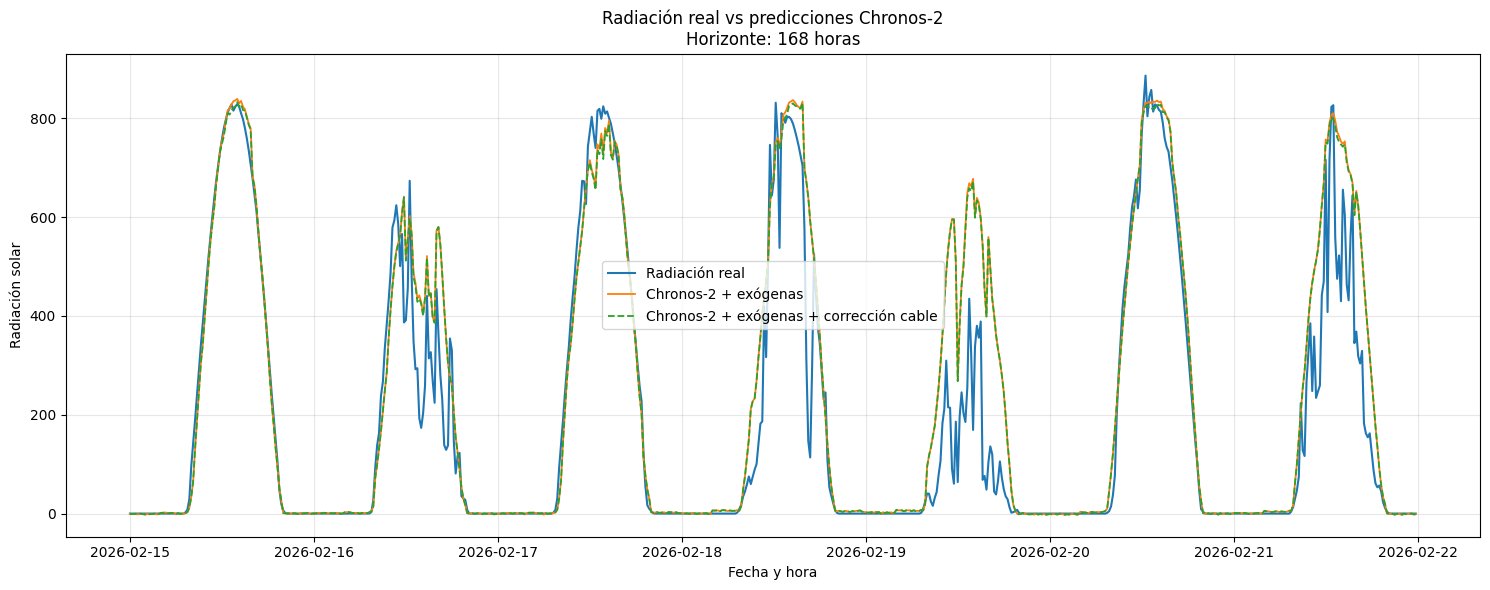

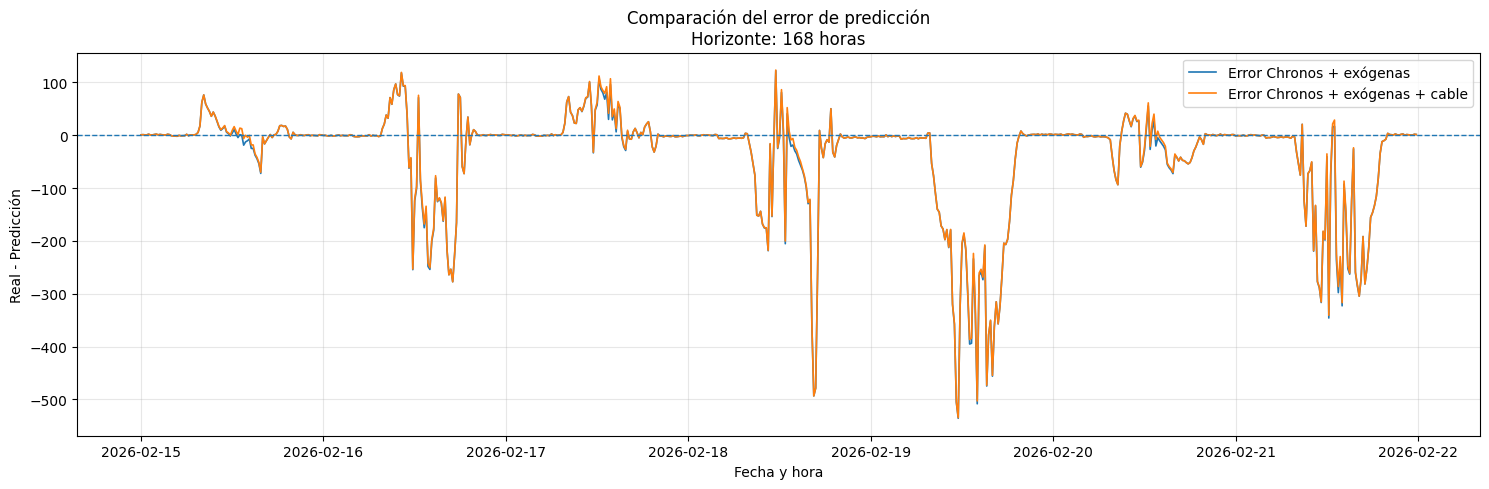

In [24]:
# ============================================================
# GRÁFICOS: CHRONOS EXÓGENAS VS EXÓGENAS + CABLE
# ============================================================

# ------------------------------------------------------------
# GRÁFICO 1: REAL VS PREDICCIONES
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    df_test.index,
    y_real,
    label="Radiación real",
    linewidth=1.5
)

plt.plot(
    df_test.index,
    pred,
    label="Chronos-2 + exógenas",
    linewidth=1.3
)

plt.plot(
    df_test.index,
    pred_cable,
    label="Chronos-2 + exógenas + corrección cable",
    linewidth=1.3,
    linestyle="--"
)

plt.title(
    f"Radiación real vs predicciones Chronos-2\n"
    f"Horizonte: {HORAS_PREDICCION} horas"
)

plt.xlabel("Fecha y hora")
plt.ylabel("Radiación solar")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "03_chronos_comparacion_cable.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# GRÁFICO 2: ERROR DE LOS DOS MODELOS
# ------------------------------------------------------------

error_exogenas = y_real - pred
error_cable = y_real - pred_cable

plt.figure(figsize=(15, 5))

plt.plot(
    df_test.index,
    error_exogenas,
    label="Error Chronos + exógenas",
    linewidth=1.2
)

plt.plot(
    df_test.index,
    error_cable,
    label="Error Chronos + exógenas + cable",
    linewidth=1.2
)

plt.axhline(
    y=0,
    linewidth=1,
    linestyle="--"
)

plt.title(
    f"Comparación del error de predicción\n"
    f"Horizonte: {HORAS_PREDICCION} horas"
)

plt.xlabel("Fecha y hora")
plt.ylabel("Real - Predicción")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "04_error_chronos_cable.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

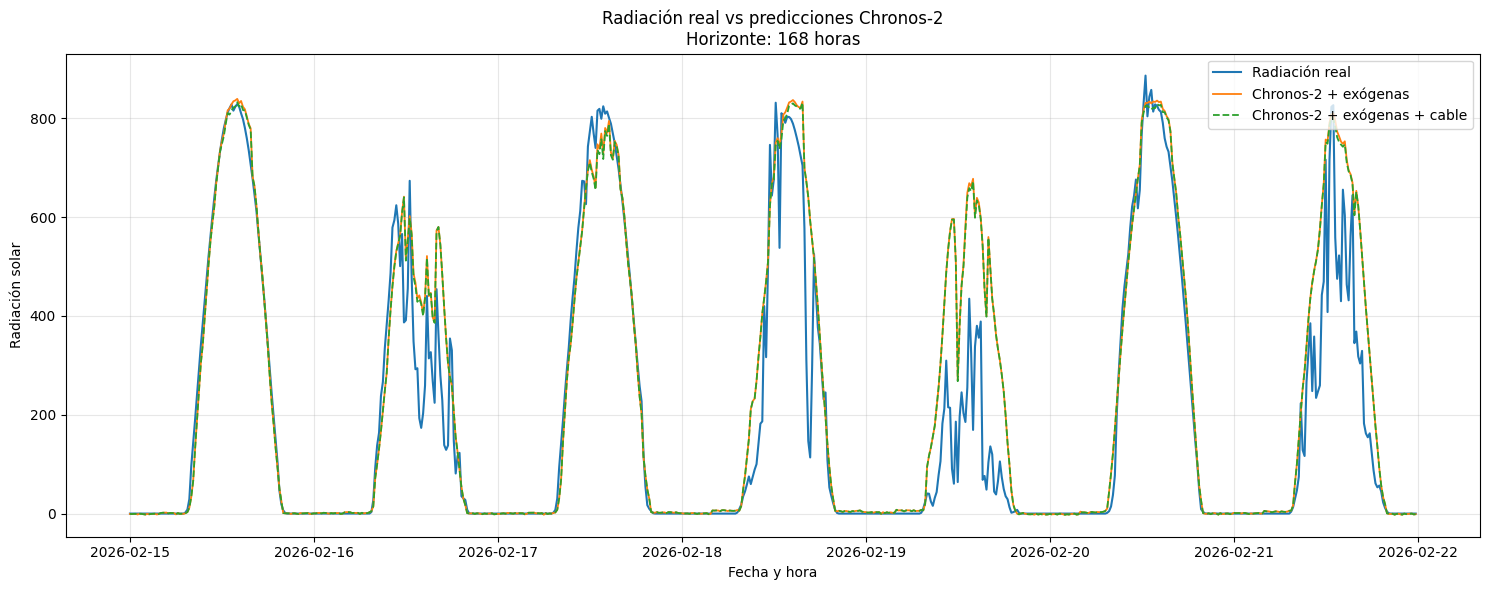

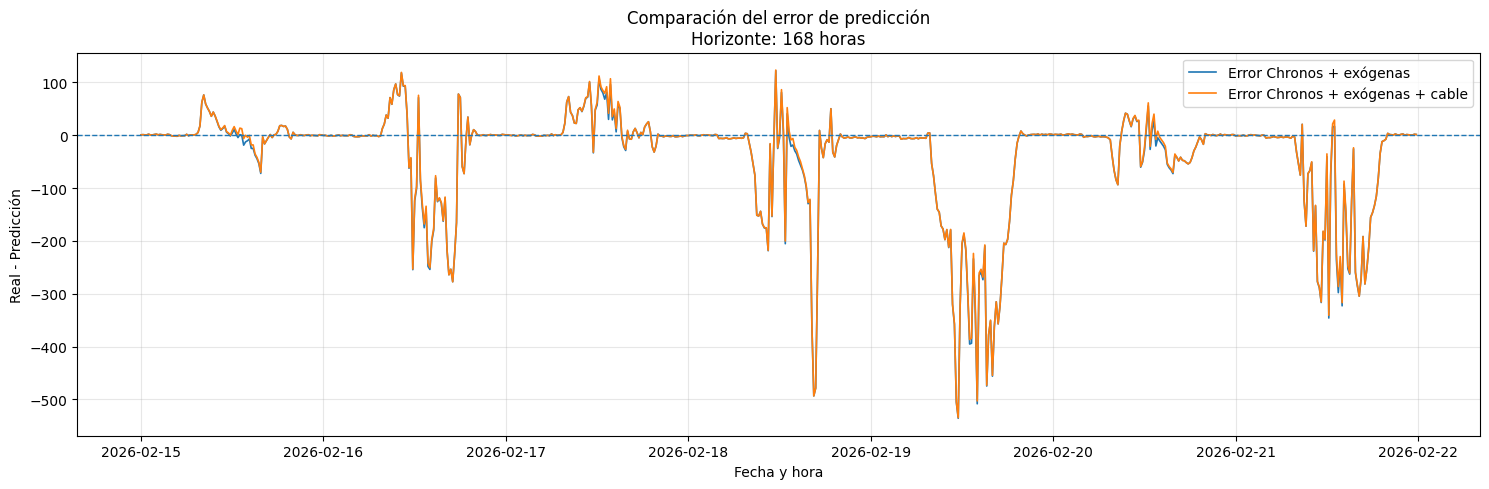

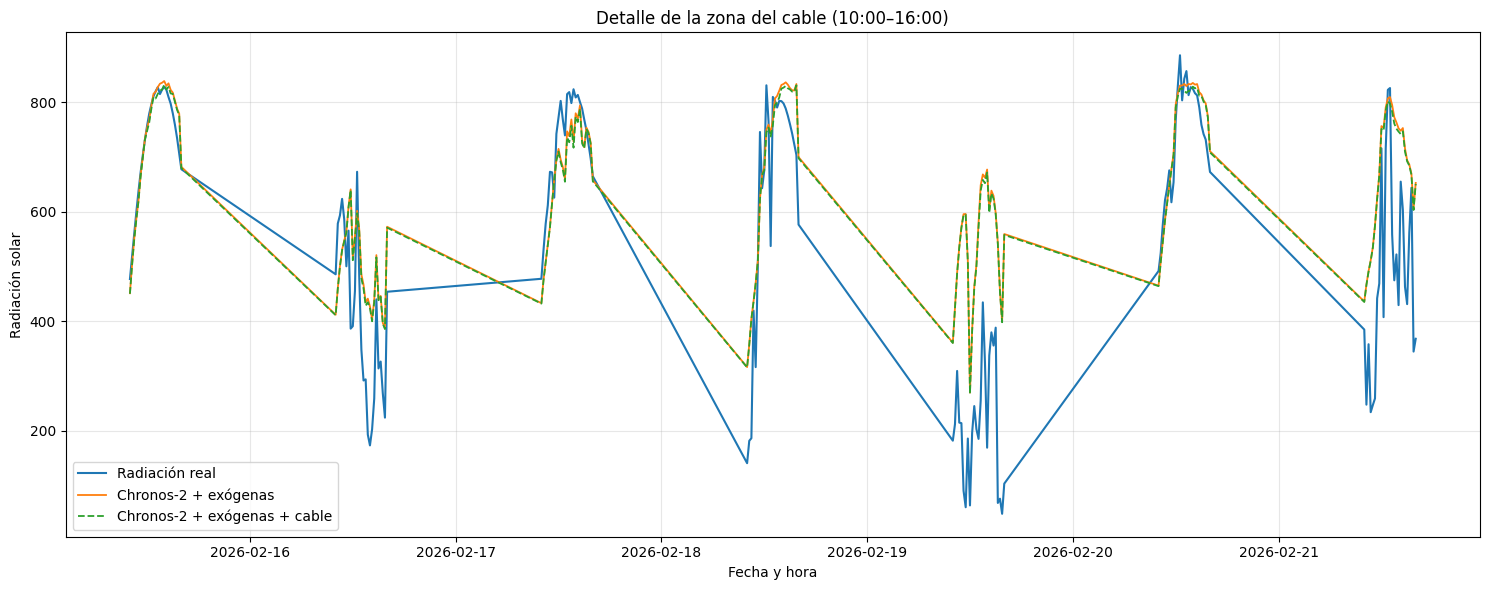


Archivos guardados en la carpeta:
resultados_chronos_cable_7dias
- metricas_comparacion_chronos.csv
- resumen_metricas.txt
- predicciones_chronos.csv
- 01_comparacion_predicciones.png
- 02_comparacion_errores.png
- 03_detalle_zona_cable.png


In [25]:
# ============================================================
# GUARDAR MÉTRICAS Y GRÁFICOS EN UNA CARPETA
# ============================================================

import os

CARPETA_SALIDA = "resultados_chronos_cable_7dias"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# ------------------------------------------------------------
# 1. TABLA DE MÉTRICAS
# ------------------------------------------------------------

metricas_comparacion = pd.DataFrame({
    "Modelo": [
        "Chronos-2 + exógenas",
        "Chronos-2 + exógenas + cable"
    ],
    "MAE": [
        mae,
        mae_cable
    ],
    "RMSE": [
        rmse,
        rmse_cable
    ],
    "WAPE": [
        wape,
        wape_cable
    ]
})

metricas_comparacion.to_csv(
    os.path.join(CARPETA_SALIDA, "metricas_comparacion_chronos.csv"),
    index=False
)

# ------------------------------------------------------------
# 2. RESUMEN TXT
# ------------------------------------------------------------

with open(
    os.path.join(CARPETA_SALIDA, "resumen_metricas.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write("RESULTADOS CHRONOS-2\n")
    f.write("=" * 50 + "\n\n")
    f.write(f"Fecha inicio test: {FECHA_INICIO_TEST}\n")
    f.write(f"Horizonte: {HORAS_PREDICCION} horas\n")
    f.write(f"Pasos: {PREDICTION_LENGTH}\n")
    f.write(f"Contexto: {DIAS_CONTEXTO} días\n\n")

    f.write("MODELO 1: CHRONOS-2 + EXÓGENAS\n")
    f.write("-" * 40 + "\n")
    f.write(f"MAE  : {mae:.4f}\n")
    f.write(f"RMSE : {rmse:.4f}\n")
    f.write(f"WAPE : {wape:.2f}%\n\n")

    f.write("MODELO 2: CHRONOS-2 + EXÓGENAS + CABLE\n")
    f.write("-" * 40 + "\n")
    f.write(f"MAE  : {mae_cable:.4f}\n")
    f.write(f"RMSE : {rmse_cable:.4f}\n")
    f.write(f"WAPE : {wape_cable:.2f}%\n")


# ------------------------------------------------------------
# 3. GUARDAR PREDICCIONES
# ------------------------------------------------------------

resultados_finales = pd.DataFrame({
    "fecha": df_test.index,
    "radiacion_real": y_real,
    "chronos_exogenas": pred,
    "chronos_exogenas_cable": pred_cable
})

resultados_finales.to_csv(
    os.path.join(CARPETA_SALIDA, "predicciones_chronos.csv"),
    index=False
)


# ------------------------------------------------------------
# 4. GRÁFICO 1: REAL VS PREDICCIONES
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(df_test.index, y_real, label="Radiación real", linewidth=1.5)
plt.plot(df_test.index, pred, label="Chronos-2 + exógenas", linewidth=1.3)
plt.plot(
    df_test.index,
    pred_cable,
    label="Chronos-2 + exógenas + cable",
    linewidth=1.3,
    linestyle="--"
)

plt.title(f"Radiación real vs predicciones Chronos-2\nHorizonte: {HORAS_PREDICCION} horas")
plt.xlabel("Fecha y hora")
plt.ylabel("Radiación solar")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(CARPETA_SALIDA, "01_comparacion_predicciones.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. GRÁFICO 2: COMPARACIÓN DE ERRORES
# ------------------------------------------------------------

error_exogenas = y_real - pred
error_cable = y_real - pred_cable

plt.figure(figsize=(15, 5))

plt.plot(df_test.index, error_exogenas, label="Error Chronos + exógenas", linewidth=1.2)
plt.plot(df_test.index, error_cable, label="Error Chronos + exógenas + cable", linewidth=1.2)

plt.axhline(y=0, linewidth=1, linestyle="--")

plt.title(f"Comparación del error de predicción\nHorizonte: {HORAS_PREDICCION} horas")
plt.xlabel("Fecha y hora")
plt.ylabel("Real - Predicción")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(CARPETA_SALIDA, "02_comparacion_errores.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. GRÁFICO 3: DETALLE DE LA ZONA DEL CABLE
# ------------------------------------------------------------

horas = df_test.index.hour + df_test.index.minute / 60
mascara_cable = (horas >= 10) & (horas <= 16)

plt.figure(figsize=(15, 6))

plt.plot(
    df_test.index[mascara_cable],
    y_real[mascara_cable],
    label="Radiación real",
    linewidth=1.5
)

plt.plot(
    df_test.index[mascara_cable],
    pred[mascara_cable],
    label="Chronos-2 + exógenas",
    linewidth=1.3
)

plt.plot(
    df_test.index[mascara_cable],
    pred_cable[mascara_cable],
    label="Chronos-2 + exógenas + cable",
    linewidth=1.3,
    linestyle="--"
)

plt.title("Detalle de la zona del cable (10:00–16:00)")
plt.xlabel("Fecha y hora")
plt.ylabel("Radiación solar")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(CARPETA_SALIDA, "03_detalle_zona_cable.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. MOSTRAR CONTENIDO DE LA CARPETA
# ------------------------------------------------------------

print("\nArchivos guardados en la carpeta:")
print(CARPETA_SALIDA)

for archivo in os.listdir(CARPETA_SALIDA):
    print("-", archivo)